# CSE 4095 — Class 3: Regression and Model Error
Use AI to help write unfamiliar code, but verify and explain each modeling decision.

## 1. Load and inspect the dataset
Upload `class1_student_habits.csv`, load it as `df`, and inspect `exam_score`.

0     64.6
1     81.5
2     92.0
3    100.0
4     68.5
Name: exam_score, dtype: float64
Count: 250
Mean: 77.15960000000001
Median: 76.95
Standard deviation: 10.330498761368425
Minimum: 51.4
Maximum: 100.0


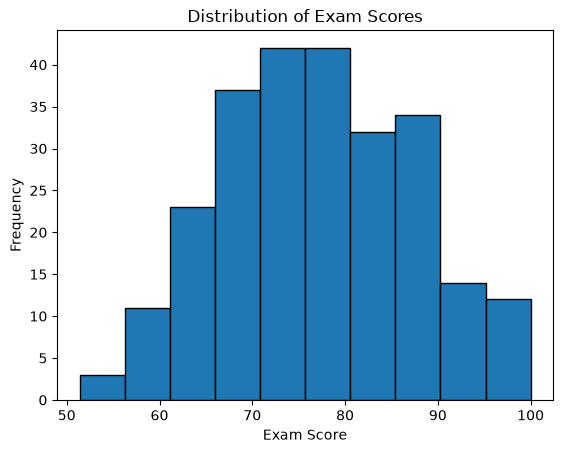

In [1]:
# TODO: load the dataset and inspect exam_score
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv("class1_student_habits.csv")

# Inspect exam_score
print(df["exam_score"].head())

# Calculate descriptive statistics
print("Count:", df["exam_score"].count())
print("Mean:", df["exam_score"].mean())
print("Median:", df["exam_score"].median())
print("Standard deviation:", df["exam_score"].std())
print("Minimum:", df["exam_score"].min())
print("Maximum:", df["exam_score"].max())

# Create a histogram of exam scores
plt.hist(df["exam_score"], bins=10, edgecolor="black")
plt.xlabel("Exam Score")
plt.ylabel("Frequency")
plt.title("Distribution of Exam Scores")
plt.show()

Part 1 Questions:

1. Why is this a regression problem?  
- This is a regression problem because we are trying to predict the actual numerical value of `exam_score`, such as 82.7, instead of predicting a category.

2. How is this different from the Class 2 classification problem?
- In Class 2, classification was used to predict a category such as Yes or No for whether a student had a high exam score. In this assignment, regression predicts the actual exam score as a number.

3. What information is lost when we convert `exam_score` into only Yes or No?
- When we convert `exam_score` into Yes or No, we lose the exact score and the differences between students' scores. For example, students with scores of 81 and 95 might both be labeled Yes even though their actual scores are quite different.

4. What kind of output should a regression model produce?
- A regression model should produce a numerical prediction, such as 82.7, rather than a category such as Yes or No.

Part 2 Questions:

1. Describe the distribution of exam scores?  
- The exam scores are centered around the upper 70s, with a mean of about 77.16 and a median of 76.95. Most scores fall roughly between 65 and 90, with fewer scores at the very low and very high ends.

2. Are there unusually low or high values?  
- The minimum exam score is 51.4 and the maximum is 100.0. These values are at the extremes of the distribution, but the histogram does not show many scores at either end.

3. Why is it useful to understand the target before trying to predict it?  
- Understanding the target helps us see the typical scores, the overall range, the amount of variation, and whether there are unusual values. This gives us useful context when we later evaluate how accurate the model's predictions are.

## 2. Explore one relationship
Plot `study_hours_per_week` versus `exam_score` and describe what you observe.

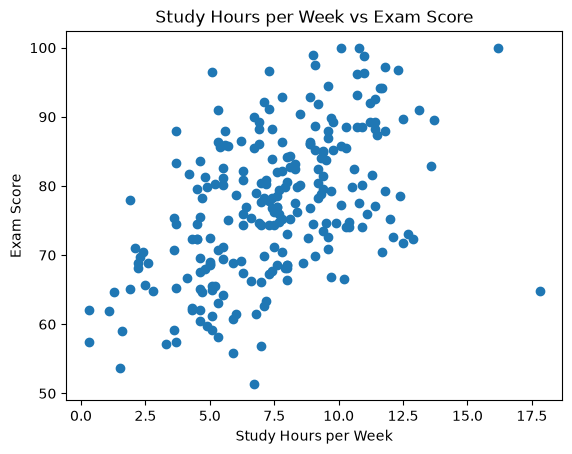

Correlation: 0.5155646432806653


In [2]:
# TODO: create the scatter plot
# Scatter plot of study hours vs exam score
plt.scatter(df["study_hours_per_week"], df["exam_score"])

plt.xlabel("Study Hours per Week")
plt.ylabel("Exam Score")
plt.title("Study Hours per Week vs Exam Score")

plt.show()

# Calculate correlation
correlation = df["study_hours_per_week"].corr(df["exam_score"])
print("Correlation:", correlation)

Part 3 Questions:

1. Does there appear to be a relationship?  
- Yes, there appears to be a moderate relationship between study hours per week and exam score. The correlation of about 0.516 also suggests a noticeable relationship between the two variables.

2. Is the relationship positive or negative?  
- The relationship is positive. In general, students who study more hours per week tend to have higher exam scores.

3. Does it appear approximately linear?  
- Yes, the relationship appears approximately linear because the points generally follow an upward trend as study hours increase. However, the points are fairly spread out, so the relationship is not very strong.

4. Are there students who do not follow the general pattern?  
- Yes, there are some students who do not follow the general pattern. For example, there are students with relatively high study hours but lower exam scores, as well as some students with fewer study hours who received relatively high scores.

## 3. Define X and y
Start without `quiz_average`. Explain why `student_id` is excluded.

In [3]:
# TODO: define feature columns, X, and y
# Define the input features
X = df[
    [
        "study_hours_per_week",
        "sleep_hours_per_night",
        "attendance_rate",
        "practice_problems_per_week",
        "prior_programming_experience",
        "study_group",
        "commute_minutes"
    ]
]

# Define the target
y = df["exam_score"]

## 4. Train/test split and preprocessing
Use an 80/20 split and a pipeline that handles missing values and categorical variables.

In [4]:
# TODO: split data and create preprocessing
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

Part 5 Questions:

1. What is the training set used for?  
- The training set is used to fit the model and help it learn patterns between the input features and the exam scores.

2. What is the test set used for?  
- The test set is used to evaluate how well the trained model performs on data that it did not see during training.

3. Why should the model not be trained using the test set?  
- The model should not be trained using the test set because the test set is supposed to represent unseen data. If the model trains on it, the evaluation would no longer be a fair measure of how well the model generalizes to new data.

4. Why should different experiments use the same split when we want to compare them fairly?  
- Different experiments should use the same training and test split so they are evaluated on the same observations. This makes the comparison fair because any difference in performance is more likely to come from the model or feature changes rather than from using different test data.

In [6]:
## Part 6 — Preprocess the Features ##

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Numerical and categorical feature names
numerical_features = [
    "study_hours_per_week",
    "sleep_hours_per_night",
    "attendance_rate",
    "practice_problems_per_week",
    "commute_minutes"
]

categorical_features = [
    "prior_programming_experience",
    "study_group"
]

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

Part 6 Questions:

1. Why do we handle numerical and categorical variables differently?  
- We handle them differently because numerical variables contain numbers that can be scaled and compared directly, while categorical variables contain labels or groups that need to be converted into a numerical form before a machine-learning model can use them.

2. What does StandardScaler do?  
- `StandardScaler` changes numerical features so they are on a similar scale by centering them around a mean of 0 and scaling them based on their standard deviation. This helps prevent features with larger numerical ranges from having too much influence on the model.

3. What does one-hot encoding do?  
- One-hot encoding converts categorical values into separate numerical columns. Each category gets its own column, usually containing 0 or 1 to show whether that category applies to a particular row.

4. Why should preprocessing be learned from the training data rather than the entire dataset?  
- Preprocessing should be learned from the training data only so that information from the test set does not leak into the model-building process. The test set should remain unseen until evaluation so that the model's performance is measured fairly.

## 5. Mean baseline
Predict the training-set mean for every test case and calculate baseline MAE.

In [7]:
# TODO: calculate mean baseline and MAE
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Calculate the mean exam score from the training set
baseline_mean = y_train.mean()

# Predict the same mean score for every test observation
baseline_predictions = np.full(len(y_test), baseline_mean)

# Calculate baseline metrics
baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_mse = mean_squared_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(baseline_mse)
baseline_r2 = r2_score(y_test, baseline_predictions)

# Display results
print("Baseline Mean:", baseline_mean)
print("Baseline MAE:", baseline_mae)
print("Baseline MSE:", baseline_mse)
print("Baseline RMSE:", baseline_rmse)
print("Baseline R²:", baseline_r2)

Baseline Mean: 77.726
Baseline MAE: 7.659199999999999
Baseline MSE: 96.079588
Baseline RMSE: 9.802019587819645
Baseline R²: -0.09107746905825942


Part 7 Question:

1. Why is this useful?  
- The baseline gives us a simple reference point to compare our regression model against. In this case, the baseline predicts the training-set mean exam score of about 77.73 for every student. Its MAE is about 7.66 points and its RMSE is about 9.80 points, so a useful regression model should ideally produce lower prediction errors than this baseline. The negative R² value also shows that this baseline does not explain the variation in the test exam scores well.

## 6. Linear regression
Fit a preprocessing + LinearRegression pipeline using training data only.

In [8]:
# TODO: build, fit, and predict
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

# Create the Linear Regression pipeline
linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regression", LinearRegression())
])

# Train the model
linear_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = linear_model.predict(X_test)

# Display several actual and predicted exam scores
results = pd.DataFrame({
    "Actual Exam Score": y_test.values,
    "Predicted Exam Score": y_pred
})

print(results.head(10))

   Actual Exam Score  Predicted Exam Score
0               72.5             76.139549
1               68.0             71.790970
2               78.3             81.646656
3               84.0             84.730618
4               69.0             65.350055
5               74.8             73.531799
6               69.1             68.664998
7               71.5             71.747859
8               70.5             80.852096
9               79.4             78.761673


Part 8 Questions:

1. What does `.fit()` do?  
- `.fit()` trains the model using the training data. It learns the relationship between the input features and the actual exam scores so it can make predictions.

2. What does `.predict()` do?  
- `.predict()` uses the trained model to estimate exam scores for new input data, such as the students in the test set.

3. Why can the predicted exam score contain decimals even if the original scores are whole numbers?  
- Linear Regression calculates predictions using a mathematical equation, so the result can be any numerical value, including decimals. The model is not limited to predicting only the exact values that appeared in the original data.

## 7. Metrics
Calculate MAE, MSE, and R². Compare with the baseline.

In [9]:
# TODO: evaluate predictions
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Calculate Linear Regression metrics
linear_mae = mean_absolute_error(y_test, y_pred)
linear_mse = mean_squared_error(y_test, y_pred)
linear_rmse = np.sqrt(linear_mse)
linear_r2 = r2_score(y_test, y_pred)

# Display Linear Regression metrics
print("Linear Regression MAE:", linear_mae)
print("Linear Regression MSE:", linear_mse)
print("Linear Regression RMSE:", linear_rmse)
print("Linear Regression R²:", linear_r2)

print()

# Compare with baseline metrics
comparison = pd.DataFrame({
    "Model": ["Mean Baseline", "Linear Regression"],
    "MAE": [baseline_mae, linear_mae],
    "MSE": [baseline_mse, linear_mse],
    "RMSE": [baseline_rmse, linear_rmse],
    "R²": [baseline_r2, linear_r2]
})

print(comparison)

Linear Regression MAE: 5.809474919936606
Linear Regression MSE: 71.32497181239688
Linear Regression RMSE: 8.445411287343967
Linear Regression R²: 0.19003535146589423

               Model       MAE        MSE      RMSE        R²
0      Mean Baseline  7.659200  96.079588  9.802020 -0.091077
1  Linear Regression  5.809475  71.324972  8.445411  0.190035


Part 9 Questions:

1. Which metric is easiest to explain in terms of exam-score points?  
- MAE is the easiest to explain because it directly represents the average prediction error in exam-score points. In this model, the MAE is about 5.81, meaning the predictions differ from the actual exam scores by about 5.81 points on average.

2. Why does MSE penalize large errors more heavily than MAE?  
- MSE squares each prediction error before averaging them. Because of this, larger errors increase much more than smaller errors, so they have a greater effect on the final MSE value.

3. Why might RMSE be easier to interpret than MSE?  
- RMSE is easier to interpret because it is expressed in the same units as the exam scores. In this case, the RMSE is about 8.45 exam-score points, while MSE is measured in squared units.

4. Did Linear Regression outperform the mean baseline?  
- Yes. Linear Regression performed better than the mean baseline on the test set. Its MAE decreased from about 7.66 to 5.81, and its RMSE decreased from about 9.80 to 8.45. Its R² also increased from about -0.09 for the baseline to about 0.19 for Linear Regression.

5. What does your R² value tell you?  
- The Linear Regression R² value is about 0.19. This means the model explains about 19% of the variation in exam scores in the test data. This is better than the mean baseline, but it also shows that much of the variation in exam scores is still not explained by the model.

## 8. Prediction table
Create actual, predicted, residual, and absolute-residual columns.

In [10]:
# TODO: build prediction/error table
# Create a prediction table while preserving test-row alignment
prediction_table = X_test.copy()

prediction_table["actual"] = y_test
prediction_table["predicted"] = y_pred

# Residual = actual - predicted
prediction_table["residual"] = (
    prediction_table["actual"] - prediction_table["predicted"]
)

# Absolute prediction error
prediction_table["absolute_error"] = prediction_table["residual"].abs()

# Display the first few rows
prediction_table.head(10)

,study_hours_per_week,sleep_hours_per_night,attendance_rate,practice_problems_per_week,prior_programming_experience,study_group,commute_minutes,actual,predicted,residual,absolute_error
142,8.8,NaN,81.6,14,Some,Yes,0,72.5,76.139549,-3.639549,3.639549
6,4.8,5.1,97.8,21,NaN,No,0,68.0,71.790970,-3.790970,3.790970
97,4.7,6.2,88.6,30,Strong,Yes,57,78.3,81.646656,-3.346656,3.346656
60,9.3,6.8,100.0,25,Some,Yes,23,84.0,84.730618,-0.730618,0.730618
112,5.0,5.6,76.5,12,Some,Yes,23,69.0,65.350055,3.649945,3.649945
181,7.7,7.8,81.2,8,Some,No,12,74.8,73.531799,1.268201,1.268201
197,6.2,4.6,82.0,11,NaN,No,47,69.1,68.664998,0.435002,0.435002
184,NaN,NaN,79.6,9,Some,Yes,8,71.5,71.747859,-0.247859,0.247859
9,11.7,6.9,91.0,4,NaN,Yes,0,70.5,80.852096,-10.352096,10.352096
104,7.7,8.0,98.8,15,NaN,Yes,0,79.4,78.761673,0.638327,0.638327


## 9. Actual vs. predicted plot
Add a perfect-prediction reference line.

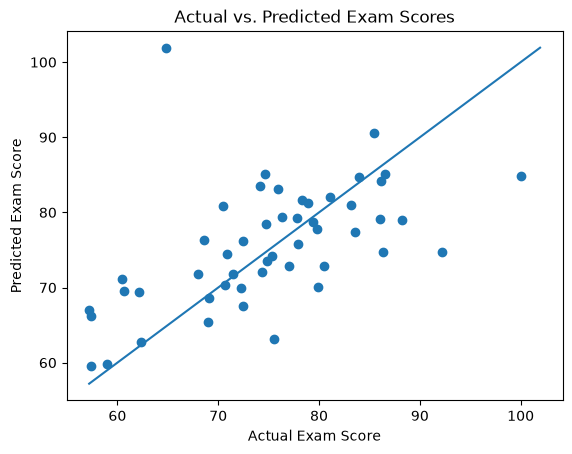

In [13]:
# TODO: actual vs predicted plot
## Actual VS Predicted Plot ##

import matplotlib.pyplot as plt

# Plot actual vs. predicted exam scores
plt.scatter(y_test, y_pred)

# Create the diagonal actual = predicted reference line
minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot([minimum, maximum], [minimum, maximum])

# Labels and title
plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")
plt.title("Actual vs. Predicted Exam Scores")

plt.show()

Part 10 Questions:

1. What would a perfect model look like on this graph?  
- A perfect model would have every point exactly on the diagonal `actual = predicted` line. That would mean every predicted exam score is exactly equal to the actual exam score.

2. Are most points close to the diagonal?  
- Many of the points are reasonably close to the diagonal, which means the model is often making predictions that are fairly close to the actual exam scores. However, there are also several points that are noticeably farther from the line.

3. Where does the model appear to make larger errors?  
- The larger errors occur at points that are farther away from the diagonal. For example, there are some students with actual scores in the mid-to-high 70s or near 100 whose predicted scores are much farther away. One clear example from the table is an actual score of 70.5 with a predicted score of about 80.85, giving an absolute error of about 10.35 points.

## 10. Residual plot
Plot predicted values against residuals and add a horizontal zero line.

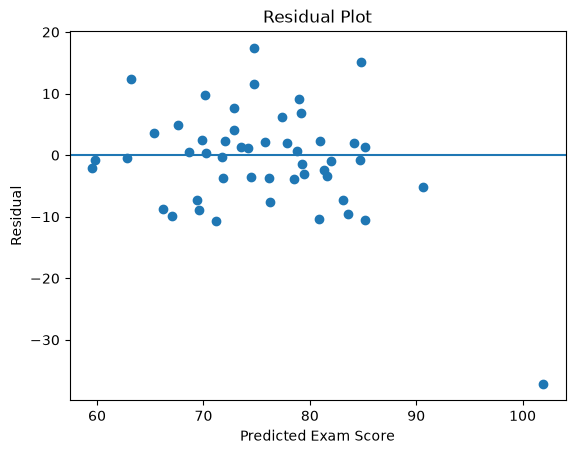

In [14]:
# TODO: residual plot
import matplotlib.pyplot as plt

# Plot predicted exam scores vs residuals
plt.scatter(y_pred, prediction_table["residual"])

# Add horizontal reference line at residual = 0
plt.axhline(y=0)

# Labels and title
plt.xlabel("Predicted Exam Score")
plt.ylabel("Residual")
plt.title("Residual Plot")

plt.show()

Part 11 Questions:

1. What does a positive residual mean?  
- A positive residual means the actual exam score was higher than the predicted exam score, so the model underestimated the student's score.

2. What does a negative residual mean?  
- A negative residual means the actual exam score was lower than the predicted exam score, so the model overestimated the student's score.

3. What does a residual close to zero mean?  
- A residual close to zero means the predicted exam score was very close to the actual exam score, so the model made a relatively accurate prediction for that student.

4. Do you see any pattern in the residual plot?  
- Most of the residuals appear scattered above and below zero without a strong systematic pattern, which is a good sign. However, there are a few larger errors, including one very large negative residual at a predicted score a little above 100. This suggests the model performs reasonably overall but still makes some substantial errors for certain students.

## 11. Largest errors
Find and inspect the ten largest absolute residuals.

In [15]:
# TODO: inspect largest errors
# Sort by largest absolute prediction error
largest_errors = prediction_table.sort_values(
    by="absolute_error",
    ascending=False
).head(10)

# Display the 10 largest errors
largest_errors[
    [
        "actual",
        "predicted",
        "residual",
        "absolute_error",
        "study_hours_per_week",
        "sleep_hours_per_night",
        "attendance_rate",
        "practice_problems_per_week",
        "prior_programming_experience",
        "study_group",
        "commute_minutes"
    ]
]

,actual,predicted,residual,absolute_error,study_hours_per_week,sleep_hours_per_night,attendance_rate,practice_problems_per_week,prior_programming_experience,study_group,commute_minutes
173,64.8,101.923760,-37.123760,37.123760,17.8,6.9,98.1,0,Strong,Yes,36
19,92.2,74.744754,17.455246,17.455246,7.1,NaN,90.0,14,Some,Yes,24
108,100.0,84.796908,15.203092,15.203092,10.1,7.3,91.6,25,NaN,Yes,0
69,75.5,63.161318,12.338682,12.338682,4.6,7.4,64.3,9,NaN,Yes,30
67,86.3,74.772910,11.527090,11.527090,5.3,6.2,98.2,22,Some,No,16
15,60.5,71.166473,-10.666473,10.666473,4.6,6.5,88.0,0,Strong,Yes,15
222,74.6,85.153036,-10.553036,10.553036,9.5,5.8,70.9,22,Strong,No,27
9,70.5,80.852096,-10.352096,10.352096,11.7,6.9,91.0,4,NaN,Yes,0
159,57.2,67.043271,-9.843271,9.843271,3.3,7.4,72.0,0,Strong,No,30
25,79.9,70.122740,9.777260,9.777260,4.9,7.6,93.8,8,Some,Yes,50


Part 12 Investigation:

1. Examine one large-error case.  
- Student 173 had an actual exam score of 64.8, but the model predicted about 101.92, giving an absolute error of about 37.12 points. The data show that this student had very high study hours at 17.8 hours per week, very high attendance at 98.1%, and strong prior programming experience, but completed 0 practice problems per week. One possible hypothesis is that the model placed too much weight on the student's high study hours, attendance, and prior experience and therefore greatly overestimated the score. However, the data do not prove that these factors caused the error.

2. Examine another large-error case.  
- Student 19 had an actual exam score of 92.2, while the model predicted about 74.74, giving an absolute error of about 17.46 points. The data show that this student studied 7.1 hours per week, had 90.0% attendance, completed 14 practice problems per week, and participated in a study group. One possible hypothesis is that the student's actual performance was stronger than what the model expected based on the available input features. There may also be other factors affecting the exam score that are not included in the model.

## Examine the Linear Regression Coefficients

In [16]:
# Get the fitted preprocessor and regression model
fitted_preprocessor = linear_model.named_steps["preprocessor"]
fitted_regression = linear_model.named_steps["regression"]

# Get transformed feature names
feature_names = fitted_preprocessor.get_feature_names_out()

# Get Linear Regression coefficients
coefficients = fitted_regression.coef_

# Create a coefficient table
coefficient_table = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients
})

# Display the table
coefficient_table

,feature,coefficient
0,num__study_hours_per_week,5.920198
1,num__sleep_hours_per_night,1.119894
2,num__attendance_rate,1.958065
3,num__practice_problems_per_week,3.104413
4,num__commute_minutes,0.361381
5,cat__prior_programming_experience_Some,-3.667113
6,cat__prior_programming_experience_Strong,3.667113
7,cat__study_group_No,0.304466
8,cat__study_group_Yes,-0.304466


Part 13 Questions:

1. Which features have positive coefficients?  
- The features with positive coefficients are `study_hours_per_week`, `sleep_hours_per_night`, `attendance_rate`, `practice_problems_per_week`, `commute_minutes`, `prior_programming_experience_Strong`, and `study_group_No`.

2. Which features have negative coefficients?  
- The features with negative coefficients are `prior_programming_experience_Some` and `study_group_Yes`.

3. Which coefficients have relatively large magnitudes?  
- The coefficient with the largest magnitude is `study_hours_per_week` at about 5.92. Other relatively large coefficients are `prior_programming_experience_Strong` and `prior_programming_experience_Some` at about ±3.67, and `practice_problems_per_week` at about 3.10.

4. What does a positive coefficient mean in this fitted model?  
- A positive coefficient means that, holding the other modeled features fixed, higher values of that feature are associated with a higher predicted exam score. It does not prove that changing that feature causes the exam score to increase.

## 12. Add quiz_average
Repeat using the same split. Compare metrics and discuss whether the feature is available at prediction time.

Part 14 Hypothesis:

- I expect adding `quiz_average` to reduce prediction error because quiz performance is likely related to how well a student performs on the final exam.

In [17]:
# TODO: quiz_average experiment
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Add quiz_average while keeping the exact same train/test rows
X_train_quiz = X_train.copy()
X_test_quiz = X_test.copy()

X_train_quiz["quiz_average"] = df.loc[X_train.index, "quiz_average"]
X_test_quiz["quiz_average"] = df.loc[X_test.index, "quiz_average"]

# Updated feature groups
numerical_features_quiz = [
    "study_hours_per_week",
    "sleep_hours_per_night",
    "attendance_rate",
    "practice_problems_per_week",
    "commute_minutes",
    "quiz_average"
]

categorical_features_quiz = [
    "prior_programming_experience",
    "study_group"
]

# Numerical preprocessing
numerical_pipeline_quiz = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline_quiz = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Updated preprocessor
preprocessor_quiz = ColumnTransformer([
    ("num", numerical_pipeline_quiz, numerical_features_quiz),
    ("cat", categorical_pipeline_quiz, categorical_features_quiz)
])

# Linear Regression pipeline with quiz_average
linear_model_quiz = Pipeline([
    ("preprocessor", preprocessor_quiz),
    ("regression", LinearRegression())
])

# Train the model
linear_model_quiz.fit(X_train_quiz, y_train)

# Make predictions on the same test observations
y_pred_quiz = linear_model_quiz.predict(X_test_quiz)

# Calculate metrics
quiz_mae = mean_absolute_error(y_test, y_pred_quiz)
quiz_mse = mean_squared_error(y_test, y_pred_quiz)
quiz_rmse = np.sqrt(quiz_mse)
quiz_r2 = r2_score(y_test, y_pred_quiz)

# Compare all three models
quiz_comparison = pd.DataFrame({
    "Model": [
        "Mean Baseline",
        "Original Linear Regression",
        "Linear Regression + quiz_average"
    ],
    "MAE": [
        baseline_mae,
        linear_mae,
        quiz_mae
    ],
    "RMSE": [
        baseline_rmse,
        linear_rmse,
        quiz_rmse
    ],
    "R²": [
        baseline_r2,
        linear_r2,
        quiz_r2
    ]
})

quiz_comparison

,Model,MAE,RMSE,R²
0,Mean Baseline,7.659200,9.802020,-0.091077
1,Original Linear Regression,5.809475,8.445411,0.190035
2,Linear Regression + quiz_average,4.651794,6.093077,0.578403


Part 14 Questions:

1. Did MAE improve?  
- Yes. MAE decreased from about 5.81 for the original Linear Regression model to about 4.65 after adding `quiz_average`. This means the average prediction error became smaller.

2. Did RMSE improve?  
- Yes. RMSE decreased from about 8.45 to about 6.09. This shows that the model made smaller prediction errors overall, including fewer or less severe large errors.

3. Did R² improve?  
- Yes. R² increased from about 0.19 to about 0.58. This means the model with `quiz_average` explains substantially more of the variation in exam scores than the original Linear Regression model.

4. Was your hypothesis supported?  
- Yes. The hypothesis was supported because MAE and RMSE both decreased while R² increased after adding `quiz_average`.

5. Would `quiz_average` actually be available at the time when the prediction is supposed to be made?  
- It depends on when the prediction is made. If the prediction is made after students have completed their quizzes but before the final exam, then `quiz_average` could be a reasonable feature. If the prediction needs to be made before any quizzes have taken place, then `quiz_average` would not be available and should not be used.

## 13. Nonlinear model
Try one nonlinear regressor, such as DecisionTreeRegressor, using the same split.

In [18]:
# TODO: nonlinear model experiment
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Create Random Forest pipeline using the original preprocessing
random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regression", RandomForestRegressor(random_state=42))
])

# Train on the same original training data
random_forest_model.fit(X_train, y_train)

# Predict on the same original test data
y_pred_rf = random_forest_model.predict(X_test)

# Calculate Random Forest metrics
rf_mae = mean_absolute_error(y_test, y_pred_rf)
rf_mse = mean_squared_error(y_test, y_pred_rf)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, y_pred_rf)

# Create comparison table
model_comparison = pd.DataFrame({
    "Model": [
        "Mean Baseline",
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        baseline_mae,
        linear_mae,
        rf_mae
    ],
    "RMSE": [
        baseline_rmse,
        linear_rmse,
        rf_rmse
    ],
    "R²": [
        baseline_r2,
        linear_r2,
        rf_r2
    ]
})

model_comparison

,Model,MAE,RMSE,R²
0,Mean Baseline,7.659200,9.802020,-0.091077
1,Linear Regression,5.809475,8.445411,0.190035
2,Random Forest,6.433480,8.345506,0.209085


Part 15 Questions:

1. Which model had the lowest MAE?  
- Linear Regression had the lowest MAE at about 5.81. Random Forest had an MAE of about 6.43, while the mean baseline had an MAE of about 7.66.

2. Which had the lowest RMSE?  
- Random Forest had the lowest RMSE at about 8.35. Linear Regression had an RMSE of about 8.45, and the mean baseline had an RMSE of about 9.80.

3. Which had the highest R²?  
- Random Forest had the highest R² at about 0.21. Linear Regression had an R² of about 0.19, while the mean baseline had a negative R² of about -0.09.

4. Did the more complicated model necessarily perform better?  
- No. Random Forest performed slightly better than Linear Regression on RMSE and R² for this dataset and this particular train/test split, but Linear Regression had the lower MAE. This shows that the more complicated model did not perform better on every evaluation metric.

Part 16 Question:

1. Does `RandomForestRegressor` require `StandardScaler`? Explain why or why not.  
- `RandomForestRegressor` generally does not require `StandardScaler` because decision trees make predictions using threshold-based splits, such as `study_hours_per_week < 8.5`. These splits depend on the ordering of the values rather than their exact scale. Standardizing a feature changes the numerical values and the threshold, but it does not change which observations are lower or higher than others. Because of this, scaling is usually unnecessary for Random Forest models, although including scaling would not necessarily prevent the model from working.

## 14. Your experiment and AI Reflection
State your expectation before running the experiment. Then summarize the evidence and reflect on one AI suggestion you evaluated.

Part 17 Experiment:

- Remove `commute_minutes` from the original Linear Regression feature set and compare the new model with the original Linear Regression model.

Hypothesis:

- I expect removing `commute_minutes` to have only a small effect on the model's prediction performance because its coefficient in the original Linear Regression model was relatively small compared with most of the other numerical features.

In [19]:
# TODO: your experiment
# Create new training and test sets without commute_minutes
X_train_no_commute = X_train.drop(columns=["commute_minutes"])
X_test_no_commute = X_test.drop(columns=["commute_minutes"])

# Updated feature groups
numerical_features_no_commute = [
    "study_hours_per_week",
    "sleep_hours_per_night",
    "attendance_rate",
    "practice_problems_per_week"
]

categorical_features_no_commute = [
    "prior_programming_experience",
    "study_group"
]

# Create preprocessing for the reduced feature set
preprocessor_no_commute = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features_no_commute),
    ("cat", categorical_pipeline, categorical_features_no_commute)
])

# Create Linear Regression pipeline
linear_model_no_commute = Pipeline([
    ("preprocessor", preprocessor_no_commute),
    ("regression", LinearRegression())
])

# Train the new model
linear_model_no_commute.fit(X_train_no_commute, y_train)

# Make predictions on the same test observations
y_pred_no_commute = linear_model_no_commute.predict(X_test_no_commute)

# Calculate metrics
no_commute_mae = mean_absolute_error(y_test, y_pred_no_commute)
no_commute_mse = mean_squared_error(y_test, y_pred_no_commute)
no_commute_rmse = np.sqrt(no_commute_mse)
no_commute_r2 = r2_score(y_test, y_pred_no_commute)

# Compare with the original Linear Regression model
experiment_comparison = pd.DataFrame({
    "Model": [
        "Original Linear Regression",
        "Linear Regression without commute_minutes"
    ],
    "MAE": [
        linear_mae,
        no_commute_mae
    ],
    "RMSE": [
        linear_rmse,
        no_commute_rmse
    ],
    "R²": [
        linear_r2,
        no_commute_r2
    ]
})

experiment_comparison

,Model,MAE,RMSE,R²
0,Original Linear Regression,5.809475,8.445411,0.190035
1,Linear Regression without commute_minutes,5.800396,8.447721,0.189592


Part 17 Results:

1. What was the result of the experiment?  
- Removing `commute_minutes` caused only a very small change in model performance. MAE improved slightly from about 5.81 to 5.80, while RMSE increased slightly from about 8.445 to 8.448 and R² decreased slightly from about 0.1900 to 0.1896.

2. How did the experiment compare with the original model?  
- The two models performed almost the same. The model without `commute_minutes` had a slightly lower MAE, but its RMSE was slightly higher and its R² was slightly lower than the original Linear Regression model.

3. Did the evidence support the hypothesis?  
- Yes. The hypothesis was supported because removing `commute_minutes` produced only very small changes in MAE, RMSE, and R². This suggests that `commute_minutes` had relatively little effect on the model's overall prediction performance in this experiment.

Part 18 — AI Reflection

1. What did you ask the AI?  
- I used AI throughout the assignment to help me build the regression analysis step by step. I asked it for help with the preprocessing pipeline, Linear Regression model, evaluation metrics, prediction and residual plots, error analysis, model coefficients, the `quiz_average` experiment, Random Forest model, and my own regression experiment.

2. What did it suggest?  
- The AI suggested using scikit-learn pipelines to handle missing values, scaling, and categorical encoding before training the models. It also helped me calculate MAE, MSE, RMSE, and R², create the required plots, find the 10 largest prediction errors, and extract the Linear Regression coefficients. For my own experiment, it suggested removing `commute_minutes` and comparing the results with the original Linear Regression model.

3. Did you accept the suggestion?  
- Yes, I accepted most of the suggestions after checking that they matched the assignment requirements. I used the suggested preprocessing and modeling approach and ran the code myself to see the actual results. I also used the suggested `commute_minutes` experiment because it tested a specific question and was one of the types of experiments allowed by the assignment.

4. How did you verify it?  
- I verified the suggestions by running each code cell and checking the outputs against the assignment instructions. I compared the calculated metrics, inspected the plots, checked the largest-error table, and made sure the models used the required features and the same train/test split. I also compared the original Linear Regression results with the `quiz_average`, Random Forest, and `commute_minutes` experiments instead of assuming that a change automatically improved the model.

5. Did you modify the AI-generated code or explanation?  
- Yes. I made sure the AI's suggestions followed the assignment rather than relying only on the starter notebook. For example, the starter notebook referred to finding five large errors, while the assignment required 10, so I followed the assignment requirement. I also used `RandomForestRegressor` for the nonlinear model because that was specifically required by the assignment. I kept the code simple and reused previously created variables where possible.

6. What did you learn?  
- I learned how a regression workflow is built from preprocessing through model evaluation. I also learned that one metric alone is not enough to judge a model. For example, Random Forest had a slightly better RMSE and R² than Linear Regression, but Linear Regression had a better MAE. I also learned how residuals and individual prediction errors can reveal problems that are not obvious from the overall metrics. Finally, the `quiz_average` experiment showed me that a feature can improve prediction performance while still needing to be considered carefully based on whether it would actually be available when the prediction is made.

AI suggestion that I questioned:

- One suggestion I questioned was that `RandomForestRegressor` generally does not require `StandardScaler`, since scaling had been an important part of the Linear Regression preprocessing. The explanation was that decision trees make threshold-based splits and depend on the ordering of feature values rather than their numerical scale. I checked this reasoning against the assignment's example and understood that scaling changes the values and thresholds but does not change their ordering. This helped me understand why preprocessing requirements can depend on the type of model being used.